# 06 · Final Run

**Goal:** score the frozen system once on the two sets nobody has looked at: TEST (597 entries from the main file) and the holdout file (800 entries with later dates, new phrasings, and a lateral hire with no billing history). Everything is graded with the same code and the same gates as notebook 05, against the same baselines.

**This notebook runs once.** The models, cutoffs, and gates were all fixed before it ran (notebook 04 and `src/evaluate.py`). Nothing is tuned or changed after seeing these results, whatever they show. A result that falls short is reported as it is.

| Set | What it checks |
|---|---|
| TEST | the same kind of entries as TRAIN and VAL, never used for any choice |
| Holdout | conditions the system never saw: later dates, reserved phrasings, a timekeeper with no history |

**Questions**
1. Do TEST and the holdout file confirm what VAL showed?
2. Does the classifier still beat the rules on entries it has never seen?
3. Does it pass the gates on both sets?
4. Where does it do worse on the holdout file, and why?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from rules import run_rules, cmid_only, score
from classifier import explain
from pipeline import load_reference, load_entries, mark_true_matters, score_entries
from evaluate import (parse_metrics, pair_metrics, headline, slice_table, add_failure_types, check_decisions,
                      stress_variants, changed_decisions, check_gates, dataset_hash, GATES, TRACKED)

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
HOLDOUT_PATH = Path("../data/synthetic_time_entries_v3_HOLDOUT.xlsx")
RESULTS_DIR = Path("../results")
SETTING = "default"     # the chosen cutoffs from notebook 04
SEED = 210
SETS = ["TEST", "HOLDOUT"]   # which sets to score ["TEST", "HOLDOUT"]; ["TEST"] scores TEST and leaves the holdout file unopened
SKIP_CLIENTS = ["Firm"]   # an ordinary word, so "firm meeting" doesn't name a client (as in notebook 00)

## 2. Load the frozen system and the two sets

- **Frozen system:** the saved models and cutoffs from notebook 04, the rule settings from notebook 03, and the gates from `src/evaluate.py`.
- **TEST:** read from the main file the same way notebooks 00 and 02 read it (`load_entries`), keeping only TEST entries. Its fingerprint has to match the one notebook 05 saved, so it's the same untouched set.
- **Holdout:** the separate file, read the same way. Its Matter Master has to match the main file's, since the models only know those 103 matters. It's only opened when `SETS` includes it, so it can stay unseen until the very end.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
val_report = json.loads((RESULTS_DIR / "05_eval_report.json").read_text())
CLIENT_COL, MATTER_COL, PHRASE_MIN = feature_config["client_col"], feature_config["matter_col"], feature_config["phrase_min"]

encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
valid_cmids = set(ref["matters"]["cmid"])

main_entries, main_answers = load_entries(DATA_PATH, ref, SKIP_CLIENTS)
test_answers = main_answers[main_answers["split"] == "TEST"].reset_index(drop=True)
test_entries = main_entries[main_entries["entry_id"].isin(test_answers["entry_id"])].reset_index(drop=True)
sets = {"TEST": (test_entries, test_answers)}
if "HOLDOUT" in SETS:
    holdout_matters = pd.read_excel(HOLDOUT_PATH, sheet_name="Matter Master", dtype=str)
    assert set(holdout_matters["CMID"]) == valid_cmids
    sets["HOLDOUT"] = load_entries(HOLDOUT_PATH, ref, SKIP_CLIENTS)

assert dataset_hash(test_answers, ["entry_id"]) == val_report["fingerprints"]["TEST ids"]
assert val_report["setting"] == SETTING
print("Cutoffs:", ref["cutoffs"])
pd.DataFrame({name: entries["source_format"].value_counts() for name, (entries, _) in sets.items()}).fillna(0).astype(int)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Cutoffs: {'auto_min': 0.93, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True}


,TEST,HOLDOUT
source_format,,
TYPED,317,452
HANDWRITTEN,124,164
PDF,107,113
EMAIL,49,71


## 3. Run every method on both sets

Each set goes through the same steps, with no labels used until scoring:
- **Classifier:** `score_entries` builds the clues, runs both models, and applies the cutoffs, exactly as for the VAL stress tests in notebook 05. Each decision then gets its reasons (`explain`).
- **Rules and CMID only:** the notebook 03 baselines, run on the same clues.

Then every decision is scored against that set's answer key.

In [4]:
runs = {}
for name, (entries, answers) in sets.items():
    pairs, top, decisions = score_entries(entries, ref)
    pairs = mark_true_matters(pairs, answers)
    decisions = explain(decisions, top, pairs, CLIENT_COL, MATTER_COL, PHRASE_MIN)
    runs[name] = {"entries": entries, "answers": answers, "pairs": pairs,
                  "classifier": score(decisions, answers).merge(entries[["entry_id", "source_format"]], on="entry_id"),
                  "rules": score(run_rules(pairs, rules_config["rules"]), answers),
                  "CMID only": score(run_rules(pairs, rules_config["rules"], cmid_only), answers)}
    print(f"{name}: {len(entries)} entries | {len(pairs):,} pairs")

TEST: 597 entries | 61,491 pairs
HOLDOUT: 800 entries | 82,400 pairs


## 4. Headline results

The same numbers as notebook 05, for each method and set. VAL is shown for comparison: VAL was used to compare versions, so TEST and the holdout file are the unbiased numbers.

In [5]:
cols = ["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "matter_accuracy",
        "multi_caught", "no_match_precision", "shortlist_hit"]
table = {(name, method): headline(run[method]) for name, run in runs.items() for method in ["CMID only", "rules", "classifier"]}
table[("VAL", "classifier")] = val_report["results"]
table = pd.DataFrame(table).T[cols].rename_axis(["set", "method"])
table.round(3)

decided_precision  ci_low  ci_high  straight_through  \
set     method                                                             
TEST    CMID only               0.705   0.645    0.764             0.466   
        rules                   0.846   0.808    0.880             0.608   
        classifier              0.971   0.954    0.987             0.643   
HOLDOUT CMID only               0.732   0.690    0.773             0.480   
        rules                   0.881   0.846    0.912             0.611   
        classifier              0.983   0.968    0.994             0.576   
VAL     classifier              0.977   0.961    0.990             0.647   

                    review_share  silent_errors  matter_accuracy  \
set     method                                                     
TEST    CMID only          0.534           82.0            0.400   
        rules              0.302           48.0            0.670   
        classifier         0.223           11.0            0.843   
HOLDOUT CMID only          0.520          103.0            0.410   
        rules              0.294           50.0            0.670   
        classifier         0.278            7.0            0.848   
VAL     classifier         0.221            8.0            0.865   

                    multi_caught  no_match_precision  shortlist_hit  
set     method                                                       
TEST    CMID only          0.000                 NaN          0.661  
        rules              0.108               0.704          0.556  
        classifier         0.676               1.000          0.774  
HOLDOUT CMID only          0.000                 NaN          0.721  
        rules              0.184               0.758          0.634  
        classifier         0.868               0.947          0.820  
VAL     classifier         0.811               0.938          0.812

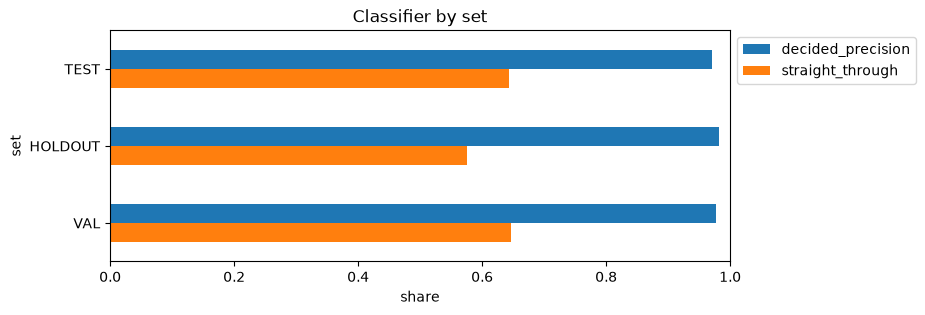

In [6]:
ax = table.xs("classifier", level="method")[["decided_precision", "straight_through"]].plot.barh(figsize=(8, 3), xlim=(0, 1), title="Classifier by set")
ax.set_xlabel("share")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

## 5. Stage by stage

Extraction (emails) and the pair model on their own, so a drop can be traced to the step it comes from.

In [7]:
stages = {}
for name, run in runs.items():
    emails = run["entries"][run["entries"]["source_format"] == "EMAIL"]
    stages[name] = {**{f"email_{k}": v for k, v in parse_metrics(emails, run["answers"], ref["client_names"]).items()},
                    **pair_metrics(run["pairs"])}
pd.DataFrame(stages).round(3)

,TEST,HOLDOUT
email_emails,49.000,71.000
email_hours_found,1.000,1.000
email_client_filled,0.796,0.789
email_right_client,0.773,0.738
email_wrong_client,0.023,0.015
entries,597.000,800.000
top_1,0.898,0.889
top_3,0.963,0.954
log_loss,0.010,0.011
calibration_error,0.046,0.070


## 6. Slices

The classifier's numbers by source format and by entry type, for each set. Small groups (under 10 entries) are left out.

In [8]:
slice_cols = ["entries", "decided_precision", "straight_through", "review_share", "silent_errors", "matter_accuracy"]
by_format = pd.concat({name: slice_table(run["classifier"], "source_format") for name, run in runs.items()})
by_format[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    EMAIL           49.0              0.941             0.694   
        HANDWRITTEN    124.0              0.975             0.637   
        PDF            107.0              0.972             0.664   
        TYPED          317.0              0.975             0.631   
HOLDOUT EMAIL           71.0              0.941             0.479   
        HANDWRITTEN    164.0              0.978             0.567   
        PDF            113.0              0.983             0.531   
        TYPED          452.0              0.989             0.606   

                     review_share  silent_errors  matter_accuracy  
TEST    EMAIL               0.204            2.0            0.776  
        HANDWRITTEN         0.250            2.0            0.879  
        PDF                 0.215            2.0            0.850  
        TYPED               0.218            5.0            0.836  
HOLDOUT EMAIL               0.380            2.0            0.690  
        HANDWRITTEN         0.293            2.0            0.848  
        PDF                 0.292            1.0            0.832  
        TYPED               0.252            2.0            0.876

In [9]:
by_type = pd.concat({name: slice_table(run["classifier"], "key_entry_category") for name, run in runs.items()})
by_type[slice_cols].round(3)

entries  decided_precision  straight_through  \
TEST    AMBIGUOUS              36.0              0.917             0.333   
        CLEAN                 154.0              1.000             0.760   
        CLOSED_OR_NOT_OPEN     15.0              1.000             0.333   
        INCOMPLETE            137.0              0.991             0.781   
        MESSY                 132.0              0.990             0.758   
        MULTI_NAMED            24.0              0.000             0.208   
        MULTI_UNNAMED          13.0              0.000             0.077   
        NO_MATCH               36.0              1.000             0.528   
        WRONG_CMID_SILENT      29.0              0.800             0.345   
        WRONG_CMID_TEXT        21.0              1.000             0.381   
HOLDOUT AMBIGUOUS              48.0              0.905             0.438   
        CLEAN                 229.0              0.994             0.699   
        CLOSED_OR_NOT_OPEN     16.0              1.000             0.312   
        INCOMPLETE            192.0              0.992             0.682   
        MESSY                 168.0              1.000             0.601   
        MULTI_NAMED            19.0                NaN             0.000   
        MULTI_UNNAMED          19.0                NaN             0.000   
        NO_MATCH               37.0              0.947             0.514   
        WRONG_CMID_SILENT      40.0              0.857             0.350   
        WRONG_CMID_TEXT        32.0              0.900             0.312   

                            review_share  silent_errors  matter_accuracy  
TEST    AMBIGUOUS                  0.667            1.0            0.694  
        CLEAN                      0.182            0.0            0.961  
        CLOSED_OR_NOT_OPEN         0.000            0.0            0.867  
        INCOMPLETE                 0.139            1.0            0.942  
        MESSY                      0.220            1.0            0.955  
        MULTI_NAMED                0.208            5.0            0.042  
        MULTI_UNNAMED              0.077            1.0            0.846  
        NO_MATCH                   0.472            0.0            0.528  
        WRONG_CMID_SILENT          0.172            2.0            0.552  
        WRONG_CMID_TEXT            0.238            0.0            0.714  
HOLDOUT AMBIGUOUS                  0.542            2.0            0.646  
        CLEAN                      0.231            1.0            0.978  
        CLOSED_OR_NOT_OPEN         0.000            0.0            0.688  
        INCOMPLETE                 0.240            0.0            0.917  
        MESSY                      0.351            0.0            0.923  
        MULTI_NAMED                0.211            0.0            0.105  
        MULTI_UNNAMED              0.053            0.0            0.737  
        NO_MATCH                   0.486            1.0            0.486  
        WRONG_CMID_SILENT          0.200            2.0            0.625  
        WRONG_CMID_TEXT            0.219            1.0            0.688

## 7. Failure types and checks

The same failure types as notebook 05, ordered by cost, and the same checks on every decision.

In [10]:
for run in runs.values():
    run["classifier"] = add_failure_types(run["classifier"])
pd.DataFrame({name: run["classifier"]["failure_type"].value_counts() for name, run in runs.items()}).fillna(0).astype(int)

,TEST,HOLDOUT
failure_type,,
false multi-matter alarm,17,37
missed second matter,6,5
"review, right matter not in shortlist",13,21
"review, top pick right",83,150
silent error,11,7
wrong flag suggestion,16,16
wrong new-client call,0,1


In [11]:
cols = ["entry_id", "source_format", "key_entry_category", "action", "pred_cmid", "key_true_cmid", "reason_short"]
pd.concat({name: run["classifier"].loc[run["classifier"]["failure_type"] == "silent error", cols] for name, run in runs.items()})

entry_id source_format key_entry_category      action pred_cmid  \
TEST    117  T-00844         TYPED        MULTI_NAMED  AUTO_MATCH  2960.001   
        149  T-01094         TYPED        MULTI_NAMED  AUTO_MATCH  8340.001   
        196  T-01366         EMAIL        MULTI_NAMED  AUTO_MATCH  8340.001   
        206  T-01412   HANDWRITTEN      MULTI_UNNAMED  AUTO_MATCH  7222.002   
        314  T-02150           PDF              MESSY  AUTO_MATCH  5524.002   
        341  T-02342         TYPED        MULTI_NAMED  AUTO_MATCH  2201.001   
        351  T-02402         EMAIL          AMBIGUOUS  AUTO_MATCH  2960.001   
        504  T-03378         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  9028.003   
        538  T-03586   HANDWRITTEN  WRONG_CMID_SILENT  AUTO_MATCH  5524.002   
        586  T-03926           PDF        MULTI_NAMED  AUTO_MATCH  2960.001   
        592  T-03960         TYPED         INCOMPLETE  AUTO_MATCH  2960.003   
HOLDOUT 16   H-00017         EMAIL          AMBIGUOUS  AUTO_MATCH  7215.005   
        105  H-00106         TYPED    WRONG_CMID_TEXT  AUTO_MATCH  5524.002   
        116  H-00117   HANDWRITTEN              CLEAN  AUTO_MATCH  7215.005   
        256  H-00257           PDF  WRONG_CMID_SILENT  AUTO_MATCH  3012.005   
        299  H-00300         EMAIL          AMBIGUOUS  AUTO_MATCH  8340.001   
        355  H-00356   HANDWRITTEN           NO_MATCH  AUTO_MATCH  7222.002   
        491  H-00492         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  7222.002   

            key_true_cmid               reason_short  
TEST    117      2960.001         Typed CMID matches  
        149      8340.001         Typed CMID matches  
        196      8340.001    Reads like past entries  
        206      7222.002  You've billed this matter  
        314      5520.004    Reads like past entries  
        341      2201.001         Typed CMID matches  
        351      2960.003    Reads like past entries  
        504      3120.003       Typed CMID corrected  
        538      4471.004       Typed CMID corrected  
        586      2960.001         Typed CMID matches  
        592      5602.001    Reads like past entries  
HOLDOUT 16       7215.003    Reads like past entries  
        105      4471.003         Typed CMID matches  
        116      7215.004       Typed CMID corrected  
        256      2960.001         Typed CMID matches  
        299      8340.002    Reads like past entries  
        355          NONE  You've billed this matter  
        491      2960.001         Typed CMID matches

In [12]:
checks = {name: check_decisions(run["classifier"], run["pairs"], valid_cmids, CLIENT_COL, MATTER_COL, PHRASE_MIN) for name, run in runs.items()}
pd.DataFrame({name: c["violations"] for name, c in checks.items()})

,TEST,HOLDOUT
check,,
suggested matters exist in Matter Master,0,0
auto-matched matter was open on the work date,0,0
auto-match against a valid typed CMID says it corrected it,0,0
NO_MATCH suggests no matter,0,0
every decision has a reason,0,0
auto-match reason is true for that entry,0,0
stated confidence matches the probability,0,0
review shortlist has 3 different matters,0,0


## 8. Stress tests

The same changes as notebook 05 (`stress_variants`), applied to each set and run through the whole pipeline again.

In [13]:
stress = {}
for name, run in runs.items():
    rows, changed = {}, {}
    for variant, changed_entries in stress_variants(run["entries"], seed=SEED).items():
        _, _, out = score_entries(changed_entries, ref)
        rows[variant] = headline(score(out, run["answers"]))
        changed[variant] = changed_decisions(run["classifier"], out)
    stress[name] = pd.DataFrame(rows).T.assign(changed=pd.Series(changed))
stress = pd.concat(stress)
stress[["decided_precision", "ci_low", "straight_through", "review_share", "silent_errors", "matter_accuracy", "changed"]].round(3)

decided_precision  ci_low  \
TEST    same, upper case narrative               0.971   0.954   
        same, extra spaces                       0.971   0.954   
        OCR noise (10% of letters)               0.969   0.953   
        typo in client name                      0.969   0.949   
        typo in narrative                        0.978   0.962   
        CMID digits swapped                      0.944   0.915   
        CMID left blank                          0.957   0.931   
        client left blank                        0.955   0.918   
        new timekeeper (no history)              0.968   0.943   
HOLDOUT same, upper case narrative               0.983   0.968   
        same, extra spaces                       0.983   0.968   
        OCR noise (10% of letters)               0.986   0.976   
        typo in client name                      0.981   0.967   
        typo in narrative                        0.984   0.973   
        CMID digits swapped                      0.960   0.942   
        CMID left blank                          0.958   0.929   
        client left blank                        0.979   0.966   
        new timekeeper (no history)              0.970   0.955   

                                     straight_through  review_share  \
TEST    same, upper case narrative              0.643         0.223   
        same, extra spaces                      0.643         0.223   
        OCR noise (10% of letters)              0.600         0.261   
        typo in client name                     0.655         0.221   
        typo in narrative                       0.615         0.251   
        CMID digits swapped                     0.571         0.367   
        CMID left blank                         0.580         0.303   
        client left blank                       0.374         0.414   
        new timekeeper (no history)             0.581         0.290   
HOLDOUT same, upper case narrative              0.576         0.278   
        same, extra spaces                      0.576         0.278   
        OCR noise (10% of letters)              0.555         0.296   
        typo in client name                     0.582         0.279   
        typo in narrative                       0.561         0.285   
        CMID digits swapped                     0.536         0.394   
        CMID left blank                         0.511         0.355   
        client left blank                       0.354         0.395   
        new timekeeper (no history)             0.541         0.312   

                                     silent_errors  matter_accuracy  changed  
TEST    same, upper case narrative            11.0            0.843    0.000  
        same, extra spaces                    11.0            0.843    0.000  
        OCR noise (10% of letters)             9.0            0.821    0.176  
        typo in client name                   11.0            0.843    0.037  
        typo in narrative                      8.0            0.826    0.111  
        CMID digits swapped                   14.0            0.811    0.226  
        CMID left blank                       15.0            0.776    0.255  
        client left blank                     10.0            0.729    0.392  
        new timekeeper (no history)            9.0            0.809    0.286  
HOLDOUT same, upper case narrative             7.0            0.848    0.000  
        same, extra spaces                     7.0            0.848    0.000  
        OCR noise (10% of letters)             5.0            0.840    0.159  
        typo in client name                    7.0            0.845    0.046  
        typo in narrative                      5.0            0.844    0.136  
        CMID digits swapped                   10.0            0.804    0.229  
        CMID left blank                       16.0            0.760    0.270  
        client left blank                      6.0            0.719    0.381  
        ne

## 9. Gates

The same blockers and tracked lines as notebook 05, from `src/evaluate.py`, with the rules baseline taken from the same set.

In [14]:
results, gate_tables = {}, {}
for name, run in runs.items():
    rules_results = headline(run["rules"])
    set_stress = stress.loc[name]
    results[name] = headline(run["classifier"]) | pair_metrics(run["pairs"]) | {
        "rules_decided_precision": rules_results["decided_precision"],
        "rules_silent_errors": rules_results["silent_errors"],
        "violations": int(checks[name]["violations"].sum()),
        "formatting_changed": max(set_stress.loc["same, upper case narrative", "changed"], set_stress.loc["same, extra spaces", "changed"]),
        "stress_worst_precision": float(set_stress["decided_precision"].min()),
        "format_worst_precision": float(by_format.loc[name, "decided_precision"].min()),
    }
    gate_tables[name] = pd.concat({"blocker": check_gates(results[name], GATES), "tracked": check_gates(results[name], TRACKED)})
    blockers = gate_tables[name].loc["blocker", "passed"]
    print(f"{name}: {blockers.sum()} of {len(blockers)} blockers passed | tracked: {gate_tables[name].loc['tracked', 'passed'].sum()} of {len(TRACKED)}")

gates = pd.concat(gate_tables)
gates[["value", "rule", "passed", "source"]]

TEST: 7 of 10 blockers passed | tracked: 1 of 2
HOLDOUT: 9 of 10 blockers passed | tracked: 2 of 2


value  \
                gate                                             
TEST    blocker decided precision, low end of range      0.954   
                silent errors per auto-match             0.030   
                decided precision above the rules        0.954   
                fewer silent errors than the rules      11.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   1.000   
                multi-matter entries caught              0.676   
                right matter in review shortlist         0.774   
                top-pick calibration error               0.046   
        tracked worst stress test, decided precision     0.944   
                worst source format, decided precision   0.941   
HOLDOUT blocker decided precision, low end of range      0.968   
                silent errors per auto-match             0.016   
                decided precision above the rules        0.968   
                fewer silent errors than the rules       7.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   0.947   
                multi-matter entries caught              0.868   
                right matter in review shortlist         0.820   
                top-pick calibration error               0.070   
        tracked worst stress test, decided precision     0.958   
                worst source format, decided precision   0.941   

                                                                                     rule  \
                gate                                                                        
TEST    blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > rules_decided_precision (0.846)   
                fewer silent errors than the rules         < rules_silent_errors (48.000)   
                decisions breaking a check                                           <= 0   
                decisions changed by formatting                                      <= 0   
                new-client calls right                                             >= 0.9   
                multi-matter entries caught                                        >= 0.7   
                right matter in review shortlist                                   >= 0.8   
                top-pick calibration error                                        <= 0.05   
        tracked worst stress test, decided precision                              >= 0.95   
                worst source format, decided precision                             >= 0.9   
HOLDOUT blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > rules_decided_precision (0.881)   
                fewer silent errors than the rules         < rules_silent_errors (50.000)   
                decisions breaking a check                                           <= 0   
                decisions changed by formatting                                      <= 0   
                new-client calls right                                             >= 0.9   
                multi-matter entries caught                                        >= 0.7   
                right matter in review shortlist                                   >= 0.8   
                top-pick calibration error                                        <= 0.05   
        tracked worst stress test, decided precision                              >= 0.95   
               

## 10. Save

- `06_final_report.json`: every number above for each set scored, the gate results, the setting, and the set fingerprints. A later run with more sets overwrites it.
- `06_decisions.csv`: one row per TEST and holdout entry for each method, with the reasons and the answer key.

In [15]:
report = {"setting": SETTING, "cutoffs": ref["cutoffs"],
          "fingerprints": {f"{name} ids": dataset_hash(answers, ["entry_id"]) for name, (_, answers) in sets.items()},
          "results": results, "gates": {name: g["passed"].droplevel(0).to_dict() for name, g in gate_tables.items()},
          "stress": {name: stress.loc[name, "decided_precision"].to_dict() for name in runs}}
(RESULTS_DIR / "06_final_report.json").write_text(json.dumps(report, indent=2, default=float))

decisions = pd.concat([run[method].assign(set=name, method=method) for name, run in runs.items() for method in ["classifier", "rules", "CMID only"]],
                      ignore_index=True)
decisions.to_csv(RESULTS_DIR / "06_decisions.csv", index=False)
print(f"Saved 06_final_report.json | 06_decisions.csv ({len(decisions):,} rows)")

Saved 06_final_report.json | 06_decisions.csv (4,191 rows)


## 11. Findings

- **TEST and the holdout file confirm VAL.** At the default setting, 97.1% of automatic decisions on TEST are right (range 95.4 to 98.7%) and 98.3% on the holdout file (96.8 to 99.4%), vs. 97.7% on VAL. The 97% target holds on entries the system never saw.
- **The classifier beats the rules on both sets:** 11 silent errors vs. 48 on TEST and 7 vs. 50 on the holdout file, with fewer entries sent to review (22% vs. 30% on TEST).
- **The holdout file sends more to review, not more errors.** 58% of holdout entries are decided with no person vs. 64% on TEST. Most of the gap is the new timekeeper: only 23% of their 94 entries are auto-matched, with no silent errors, since there's no billing history to lean on.
- **Pair model:** the right matter is ranked first for about 9 in 10 entries on both sets and in the top three for 95 to 96%.
- **Multi-matter entries:** 68% are caught on TEST and 87% on the holdout file. 6 of TEST's 11 silent errors are multi-matter entries auto-matched to their main matter, so the second matter's time is missed.
- **Slices:** typed, PDF, and handwritten entries stay between 97% and 99%. Emails trail at 94% on both sets and go to review more often on the holdout file.
- **Checks:** every decision on both sets follows every rule.
- **Stress tests:** formatting changes nothing. Messier input keeps precision between 94% and 99%, mostly by sending more to review. Swapped CMID digits are the hardest change on TEST (94.4%).
- **Gates:** 7 of 10 blockers pass on TEST and 9 of 10 on the holdout file. On TEST, silent errors per auto-match (3.0% vs. a 3% line), multi-matter caught (68% vs. 70%), and the review shortlist (77% vs. 80%) fall just short, and the worst stress test misses its tracked line (94.4% vs. 95%). On the holdout file, only calibration misses (0.070 vs. 0.05), in the safe direction: low-confidence picks are right about 47% of the time while claiming about 22%. No line was moved.

## Limitations

- Everything is synthetic, since firms can't share real time entries for privacy reasons. The holdout file's new phrasings and new timekeeper are the closest check on unfamiliar data, but they come from the same generator.
- Past narratives come from TRAIN entries only, so holdout entries are compared with history that is a few months older than they are, as a firm's would be.
- TEST was scored once before a one-line fix to the narrative splitter, which didn't treat hours written in capitals ("(0.6 HRS)") as a break. No TEST or holdout entry is written that way, so only the uppercase stress test changed (1 decision before the fix, 0 after). Nothing else changed between the two runs.
- Multi-matter entries make up about 6% of the synthetic data, more than real firms see, so the overall numbers are likely on the conservative side. Each set has only about 37 of them, so one entry moves the multi-matter numbers by about 3 points.

## Next steps

- Confirm the team-judgment gate lines with billing staff, especially the multi-matter and shortlist lines that TEST missed by a few points.
- Add a calibration step if the confidence shown to reviewers needs to be exact.
- Before a firm relies on it, refit the models and cutoffs on the firm's own history, and send a small random sample of auto-matches to review to track the real error rate.